<a href="https://colab.research.google.com/github/MSGamgee85/Projetos/blob/main/Gestao_Risco_Credito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Google Colab](https://img.shields.io/badge/Google%20Colab-F9AB00?logo=googlecolab&logoColor=fff)](#) 	[![Python](https://img.shields.io/badge/Python-3776AB?logo=python&logoColor=fff)](#) [![GitHub](https://img.shields.io/badge/GitHub-%23121011.svg?logo=github&logoColor=white)](#)

---

## **Gestão de Risco de Crédito**

---

<u>Risco de crédito</u> é o risco de que ocorra **calote** do tomador de recursos, de tal forma que os juros e o principal não serão pagos ao credor. Instituições financeiras buscam mitigar esse risco através do provisionamento de recursos para cobrir as perdas.

Com base nos conceitos de gestão de risco de crédito apresentados nos livros-texto de Hull e Schroeck (vide referências), o provisionamento e o capital econômico são calculados utilizando-se as <u>métricas</u> de **Perda Esperada (Expected Loss - EL)** e **Perda Não Esperada (Unexpected Loss - UL)**, respectivamente.

<br>

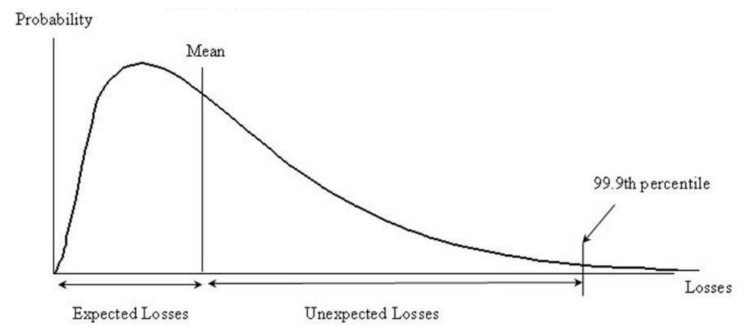

---

<small> **Figura 1.** Distribuição probabilística de perdas para Risco de Crédito. Fonte: JURČA, P. Quantitative methods in risk management. Faculty of Mathematics, Physics and Informatics. Comenius University of Bratislava. Disponível em < http://www.iam.fmph.uniba.sk/institute/jurca/ > Acesso em: 02 maio 2026 </small>

<br>

É importante conhecer alguns **conceitos fundamentais** da gestão de risco de crédito:

<br>

1. **Provisionamento**: É o valor reservado que representa o <u>custo médio</u> previsível (Perda Esperada - EL) de uma <u>operação de crédito</u>.

2. **Capital Econômico**: É o montante de recurso próprio destinado a absorver perdas que excedem a média, conhecidas como Perdas Não Esperadas (UL); representam a <u>volatilidade do risco</u>.

<br>

Em resumo, o provisionamento é calculado sobre a <u>média das perdas previstas (EL)</u>, enquanto o capital econômico é dimensionado para suportar a <u>variabilidade dessas perdas (UL)</u>, garantindo a **solvência** (liquidez) da instituição financeira em cenários adversos. $\blacksquare$

<br>


## **Configuração do ambiente**
---

In [ ]:
# Bibliotecas utilizadas
import numpy as np                # funções matemáticas e operações com vetores e matrizes
import matplotlib.pyplot as plt   # geração e visualização de gráficos
import pandas as pd               # estruturas tabulares de organização e análise de dados
import warnings                   # gestão de avisos e alertas
warnings.filterwarnings('ignore') # ignora avisos e alertas
from scipy.stats import norm      # distribuição normal da biblioteca scipy
from scipy.optimize import fsolve # encontra raízes de equações não-lineares do tipo f(x) = 0 a partir de uma estimativa

## **1. Portfólio com Ativos Descorrelacionados**

---

<u>Conceitos e Fórmulas</u>:
1. **Perda Esperada (EL)**: É a média da distribuição de perdas. Representa o valor que a instituição espera perder, em média, em suas operações de crédito:

&emsp;&emsp; $\boxed{\sf EL=EAD⋅PD⋅LGD}$ <br>

onde:

* $\sf EAD =$ `exposure at default` = exposição ao calote = valor do crédito/empréstimo concedido ao tomador
* $\sf PD =$ `probability of default` = probabilidade do calote
* $\sf LGD =$ `loss given default` = perda devido ao calote = estimativa da porcentagem do crédito/empréstimo que será perdida no caso de calote
* $\sf RR =$ `recovery rate` = taxa de recuperação = porcentagem do crédito/empréstimo que será recuperada: $\boxed{\sf RR = 1 - LGD}$

&emsp;&emsp; A perda esperada para o portfólio é dada por:

&emsp;&emsp; $\boxed{\sf EL_{P}=\displaystyle \sum_{i=1}^n EL_i}$

2. **Perda Não Esperada (UL)**: Representa a variabilidade (desvio padrão = volatilidade) da perda em torno da média

&emsp;&emsp; Para um ativo:

&emsp;&emsp; $\boxed{\sf UL=EAD \cdot \sqrt{PD \cdot σ^2_{LGD}+LGD^2 \cdot PD(1−PD)}}$

&emsp;&emsp; Para um portfólio com ativos descorrelacionados ($ρ=0$): <br>

&emsp;&emsp; $\boxed{\sf UL_{P} = \sqrt{\displaystyle \sum_{i=1}^n (UL_i)^2}}$

In [ ]:
# -- Parâmetros (estudo de caso) --
ead = 1                                 # exposição (em forma de fração do capital)
sigma_lgd = 0.25                        # variação (volatilidade) das perdas devido ao calote (em fração)
pd_portfolio = np.linspace(0, 0.2, 100) # discretização intervalo PD_média do portfólio
lgd_valores = [0.25, 0.5, 0.75]         # valores de LGD para estudo de caso

In [ ]:
# -- Funções Perda Esperada e Não Esperada --
def el(ead, pd, lgd):             # define a função da EL e suas variáveis
    return ead * pd * lgd         # fórmula da EL

def ul(ead, pd, lgd, sigma_lgd):                                     # define a função da UL e suas variáveis
    return ead * np.sqrt(pd * sigma_lgd**2 + lgd**2 * pd * (1 - pd)) # fórmula da UL

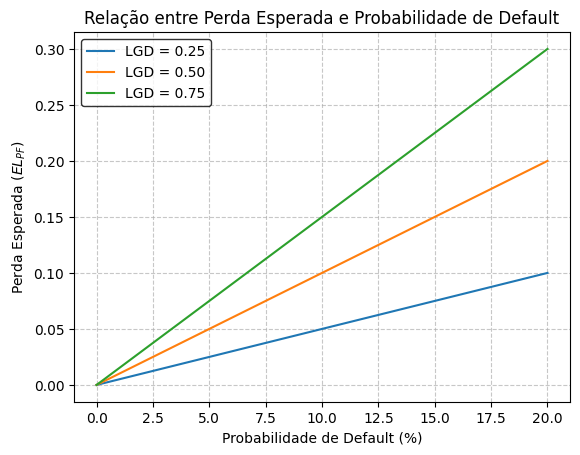

In [ ]:
# -- Gráfico EL x PD --
for lgd in lgd_valores:                                         # estrutura de repetição que calcula a EL do portfólio para cada valor de LGD
    el_pf = 2 * el(ead, pd_portfolio, lgd)                      # 2 ativos (EL_1 + EL_2 = 2*EL)
    plt.plot(pd_portfolio*100, el_pf, label=f'LGD = {lgd:.2f}') # gera as curvas de PD x EL_pf

plt.title('Relação entre Perda Esperada e Probabilidade de Default')               # título do gráfico
plt.xlabel('Probabilidade de Default (%)')                                         # título do eixo horizontal
plt.ylabel('Perda Esperada ($EL_{PF}$)')                                           # título do eixo vertical
plt.legend(edgecolor='black')                                                      # exibe a caixa de legenda com contorno em preto
plt.grid(True, linestyle='--', alpha=0.7)                                          # exibe grade no formato '---' com opacidade de 70%
plt.show()                                                                         # mostra a figura (padrão 6,4 x 4,8 pols)

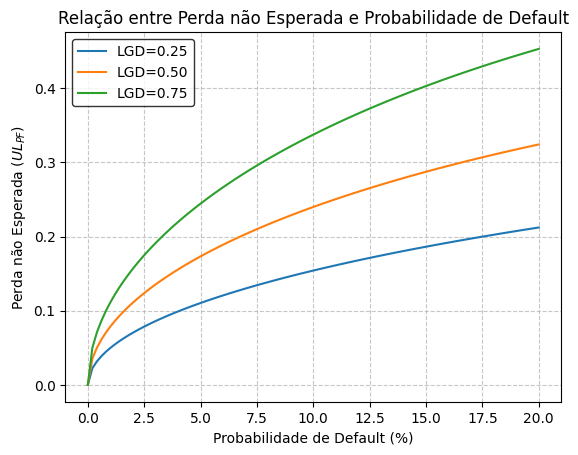

In [ ]:
# -- Gráfico UL x PD --
for lgd in lgd_valores:                                       # estrutura de repetição que calcula UL individual e UL do portfólio para cada valor de LGD
    ul_i = ul(ead, pd_portfolio, lgd, sigma_lgd)              # função da UL individual
    ul_pf = np.sqrt(2 * ul_i**2)                              # fórmula da UL com ativos descorrelacionados
    plt.plot(pd_portfolio*100, ul_pf, label=f'LGD={lgd:.2f}') # gera as curvas de PD x UL_pf

plt.title('Relação entre Perda não Esperada e Probabilidade de Default')      # título do gráfico
plt.xlabel('Probabilidade de Default (%)')                                    # título do eixo horizontal
plt.ylabel('Perda não Esperada ($UL_{PF}$)')                                  # título do eixo vertical
plt.legend(edgecolor='black')                                                 # exibe a caixa de legenda com contorno em preto
plt.grid(True, linestyle = '--', alpha=0.7)                                   # exibe grade no formato '---' com 70% de opacidade
plt.show()                                                                    # mostra a figura

In [ ]:
# Efeito de sigma_LGD na UL
pd_fixo = 0.04                                # 4% (estudo de caso)
sigma_lgd_intervalo = np.linspace(0, 1, 100)  # intervalo da sigma_LGD = [0, 1]

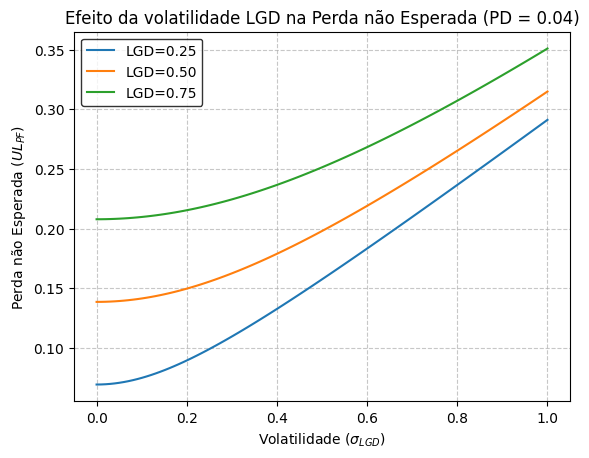

In [ ]:
# -- Gráfico UL x sigma_LGD --
for lgd in lgd_valores:                                             # estrutura de repetição que calcula UL individual e UL do portfólio para cada valor de LGD
    ul_i = ul(ead, pd_fixo, lgd, sigma_lgd_intervalo)               # função da UL individual
    ul_pf = np.sqrt(2 * ul_i**2)                                    # fórmula da UL com ativos descorrelacionados
    plt.plot(sigma_lgd_intervalo, ul_pf, label=f'LGD={lgd:.2f}')    # gera as curvas de sigma_LGD x UL_pf

plt.title(f'Efeito da volatilidade LGD na Perda não Esperada (PD = {pd_fixo})')   # título do gráfico
plt.xlabel('Volatilidade ($\sigma_{LGD}$)')                                       # título do eixo horizontal
plt.ylabel('Perda não Esperada ($UL_{PF}$)')                                      # título do eixo vertical
plt.legend(edgecolor='black')                                                     # exibe caixa de legenda com contorno em preto
plt.grid(True, linestyle='--', alpha=0.7)                                         # exibe grade no formato '---' com 70% de opacidade
plt.show()                                                                        # mostra a figura (padrão 6,4 x 4,8 pols)

### **Análise dos Resultados**

---

* O gráfico da $\sf EL$ é linear em relação à $\sf PD$ e à $\sf LGD$. Como os ativos são idênticos, a perda dobra em relação ao ativo individual. O aumento da severidade ($\sf LGD$) inclina a reta da perda esperada

* A $\sf UL$ cresce de forma côncava (formato de raiz quadrada) com a $\sf PD$. Isso ocorre porque a incerteza do default aumenta rapidamente no início, mas o termo $\sf PD \cdot (1 − PD)$ atinge um pico (em $\sf 0.5$, fora do intervalo $\sf [0, 0.2]$).

* Conforme $\sf σ_{LGD}$
aumenta, a incerteza sobre quanto será recuperado em caso de default cresce, elevando diretamente a $\sf UL$. O efeito é mais pronunciado para $\sf LGDs$ menores em termos proporcionais, mas a $\sf UL$ total é sempre maior para $\sf LGDs$ elevados.

## **2. Portfólio com Ativos Correlacionados**

---

<u>Conceitos e Fórmulas</u>:

&emsp; &emsp; Neste caso, a $\sf LGD$ é **determinística** e, portanto, $\sf σ_{LGD}=0$, temos:

&emsp; &emsp; $\sf UL = EAD \cdot \sqrt{PD \cdot 0 + LGD^2 \cdot PD(1-PD)}$

&emsp; &emsp; $\boxed{\sf UL = EAD \cdot LGD \cdot \sqrt{PD(1-PD)}}$

* **UL com Correlação (ρ)**: Quando os ativos são correlacionados, o risco do portfólio depende de como os defaults ocorrem simultaneamente:

&emsp; &emsp; $\boxed{\sf UL_{PF}=\sqrt{(UL_1)^2+(UL_2)^2+2⋅ρ_{1,2}⋅UL_1 ⋅ UL_2}}$

&emsp; &emsp; onde:

* $\sf \rho_{1,2} =$ correlação entre defaults dos ativos 1 e 2



In [ ]:
# -- Parâmetros (estudo de caso) --
pd1 = 0.02                        # 2%
pd2 = 0.04                        # 4%
lgds = [0, 0.25, 0.5, 0.75, 1.0]  # valores de LGD para estudo de caso
rho = np.linspace(-1, 1, 100)     # discretização do intervalo de rho

In [ ]:
# -- Cálculo das UL individuais --
def ul_cor(ead, pd, lgd):                         # define a função da UL individual "correlacionada"
    return ead * lgd * np.sqrt(pd * (1 - pd))     # fórmula UL individual para sigma_lgd = 0

ul1_valores = [ul_cor(1, pd1, l) for l in lgds]   # calcula UL individuais para cada valor de LGD e PD1 fixo
ul2_valores = [ul_cor(1, pd2, l) for l in lgds]   # calcula UL individuais para cada valor de LGD e PD2 fixo

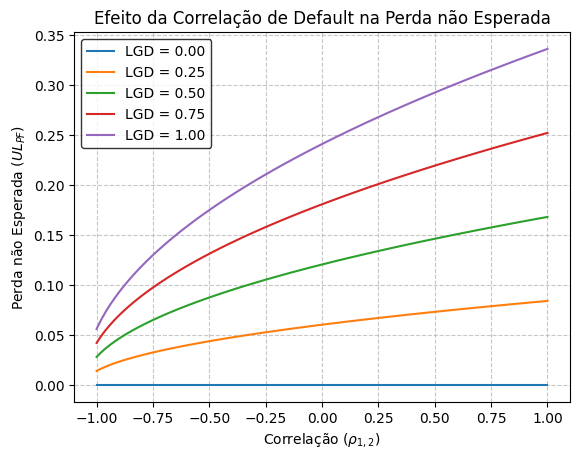

In [ ]:
# -- Gráfico UL x rho --
for i, lgd in enumerate(lgds):                                                                         # estrutura de repetição que calcula UL do portfólio para cada valor de LGD
    ul_pf = np.sqrt(ul1_valores[i]**2 + ul2_valores[i]**2 + 2 * rho * ul1_valores[i] * ul2_valores[i]) # fórmula UL com correlação
    plt.plot(rho, ul_pf, label=f'LGD = {lgd:.2f}')                                                     # gera as curvas de rho x UL_pf

plt.title('Efeito da Correlação de Default na Perda não Esperada')    # título do gráfico
plt.xlabel('Correlação ($\\rho_{1,2}$)')                              # título do eixo horizontal
plt.ylabel('Perda não Esperada ($UL_{PF}$)')                          # título do eixo vertical
plt.legend(edgecolor='black')                                         # exibe caixa de legenda com contorno em preto
plt.grid(True, linestyle = '--', alpha=0.7)                           # mostra grade no formato '---' com 70% de opacidade
plt.show()                                                            # mostra a figura (padrão 6,4 x 4,8 pols)

### **Análise dos Resultados**

---

* <u>Efeito da LGD</u>: A $\sf UL$ escala linearmente com a $\sf LGD$ quando esta é determinística. Se $\sf LGD=0$, o risco é zero; se $\sf LGD=1$, o risco é máximo.
* <u>Diversificação</u>: A diversificação é maximizada quando a correlação é mínima ($\sf ρ=−1$). O risco é minimizado em situações de correlação negativa, pois o default de um ativo tende a ser compensado pela sobrevivência do outro.
* <u>Correlação Perfeita</u>: Para $\sf ρ=1$, as perdas são perfeitamente aditivas ($\sf UL_{PF}=UL_1+UL_2$), eliminando o benefício da diversificação.
* <u>Correlação Negativa</u>: Mesmo com $\sf ρ=−1$, a $\sf UL
_{PF}>0$ porque as $\sf ULs$ individuais são diferentes ($\sf PD_1 \neq PD_2$). Para o risco ser zero com $\sf ρ=−1$, as posições teriam que ser idênticas para se anularem perfeitamente.

## **3. Modelo de Merton para Risco de Crédito**

---

<u>Conceitos e Fórmulas</u>:

1. O modelo de Merton trata o patrimônio líquido _ <i>equity</i> _ ($\sf E_t$) como uma **opção de compra** sobre os ativos ($\sf A_t$) da empresa no instante t:

&emsp;&emsp; $\boxed{\sf E_t(r, T, L, A, \sigma_A)=A_t N(d_1)−Le^{−rT}N(d_2)}$

&emsp;&emsp; onde:

- $\sf L=$ montante de juros e principal da dívida a ser paga no tempo T (*Liability* = "passivo");

- $\sf d_1 = \dfrac{ln(\frac{A_t}{L})+(r+\frac{\sigma^2_A}{2})T}{\sigma_A \sqrt{T}}$

- $\sf d_2 = d_1 - \sigma_A \sqrt{T}$

- $\sf σ_E =\frac{σ_A N(d_1)A_t}{E_t}$ = volatilidade instantânea do patrimônio líquido (<i>equity</i>)<br>

- $\sf \sigma_A =$ volatilidade dos ativos (suposta constante)

2. <b>Distância ao Default</b> ($\sf DD$): Mede quantos desvios padrões o valor da empresa está do ponto de insolvência:

&emsp; &emsp; $\boxed{\sf DD=\dfrac{ln(A_t)+(\mu -\frac{\sigma^2_A}{2})T-ln(L)}{\sigma_A \sqrt{T}}}$

&emsp; &emsp; A DD pode ser interpretada como o resultado (valor de saída) do modelo de Merton. Quanto menor o valor de DD, mais provável o risco de calote da empresa.

3. <b>Probabilidade de Defaut ($\sf PD$):</b> é calculada a partir da distribuição normal da distância ao default:

&emsp; &emsp; $\boxed{\sf PD=N(−DD)}$

&emsp; &emsp; onde:

- $\sf N(\cdot)=$ distribuição de probabilidade normal


In [ ]:
# -- Parâmetros (estudo de caso) --
Et = 25000                                      # valor do equity (patrimônio líquido)
L = 50000                                       # valor do liability (passivo)
r = 0.04                                        # taxa de juros livre de risco = 4% a.a.
T = 1                                           # prazo de vencimento (1 ano)
sigma_e_fixo = 0.4                              # volatilidade do equity = 40%
sigma_a_intervalo = np.arange(0.1, 0.31, 0.01)  # intervalo de sigma_A = volatilidade dos ativos

In [ ]:
# -- Define as equações do modelo de Merton para risco de crédito --

def merton_eqs(valor_ativo, Et, sigma_e, L, r, T, sigma_a_val):   # define a função de Merton e sua variáveis
    At = float(valor_ativo[0])                                    # valor dos ativos
    d1 = (np.log(At / L) + (r + 0.5 * sigma_a_val**2) * T) / (sigma_a_val * np.sqrt(T)) # fórmula para cálculo da variável d1 do modelo
    d2 = d1 - sigma_a_val * np.sqrt(T)                                                  # fórmula para cálculo da variável d2 do modelo
    eq = sigma_a_val * norm.cdf(d1) * At / Et - sigma_e                                 # fórmula para cálculo do equity (patrimônio líquido)
    return [eq]                                                                         # armazena valor do equity calculado no vetor

In [ ]:
# -- Solução da equação de Merton --

at_sols = []                                                                  # cria variável vetor que vai receber as soluções do modelo
for sa in sigma_a_intervalo:                                                  # estrutura de repetição que calcula as soluções
    # Estimativa inicial: At = Et + L (necessário para a função fsolve)
    sol = fsolve(merton_eqs, [Et + L], args=(Et, sigma_e_fixo, L, r, T, sa))  # função fsolve do scipy que calcula as raízes de uma equação não linear
    at_sols.append(sol[0])                                                    # adiciona as soluções encontradas ao vetor

In [ ]:
# -- Calcula DD e PD --

at_sols = np.array(at_sols)                                                                                  # armazena soluções no vetor
d1 = (np.log(at_sols / L) + (r + 0.5 * sigma_a_intervalo**2) * T) / (sigma_a_intervalo * np.sqrt(T))         # calcula a varíavel d1
dd = (np.log(at_sols) + (r - 0.5 * sigma_a_intervalo**2) * T - np.log(L)) / (sigma_a_intervalo * np.sqrt(T)) # calcula o valor de DD
probd = norm.cdf(-dd)                                                                                        # calcula o valor de PD a partir de DD

# -- Calcula PD e sigma_E --

def pd_merton(sigma_e_val, sigma_a_alvo): # define a função de Merton para cálculo
    sol = fsolve(merton_eqs, [Et + L], args=(Et, sigma_e_val, L, r, T, sigma_a_alvo))                         # função fsolve do scipy
    At_val = sol[0]                                                                                           # extrai o valor escalar da solução
    dd_val = (np.log(At_val) + (r - 0.5 * sigma_a_alvo**2) * T - np.log(L)) / (sigma_a_alvo * np.sqrt(T))     # calcula o DD
    return norm.cdf(-dd_val)                                                                                  # calcula o valor PD a partir de DD

In [ ]:
# -- Criação de tabela com os resultados --

df_resultados = pd.DataFrame({      # gera o dataframe
    'σ_A': sigma_a_intervalo,       # coluna sigma_A
    'A_t': at_sols,                 # coluna A_t
    'DD': dd,                       # coluna DD
})

display(df_resultados.head())       # mostra 5 primeiras linhas da tabela
print('\n...\n')                    # mostra '...' e pula duas linhas para melhor legibilidade
display(df_resultados.tail())       # mostra as 5 últimas linhas da tabela

,σ_A,A_t,DD
0,0.10,100000.000000,7.281472
1,0.11,90909.091128,5.743518
2,0.12,83333.471487,4.530227
3,0.13,76931.795792,3.557279
4,0.14,71555.395570,2.776064



...



,σ_A,A_t,DD
16,0.26,53819.656944,0.306984
17,0.27,53205.141213,0.243267
18,0.28,52609.055493,0.184519
19,0.29,52028.120425,0.130039
20,0.30,51459.863391,0.079264


In [ ]:
# -- Cálculo de PD para valores específicos de sigma_E e sigma_A --

sigma_e_valores = [0.4, 0.3, 0.2]                                       # volatilidade do equity (40%, 30%, 20%)
sigma_a_alvo = 0.3                                                      # volatilidade dos ativos = 30%

pd_calculados = [pd_merton(se, sigma_a_alvo) for se in sigma_e_valores] # calcula PD para cada sigma_E

df_resultados = pd.DataFrame({                                          # cria o DataFrame com os resultados formatados
    'σ_E': sigma_e_valores,                                             # coluna sigma_E
    'σ_A': [sigma_a_alvo] * len(sigma_e_valores),                       # coluna sigma_A
    'PD (%)': pd_calculados                                             # coluna PD
})

df_resultados['PD (%)'] = df_resultados['PD (%)']*100                   # formata a coluna PD em % para melhor leitura
display(df_resultados)                                                  # exibe a tabela

,σ_E,σ_A,PD (%)
0,0.4,0.3,46.841139
1,0.3,0.3,58.736628
2,0.2,0.3,71.569876


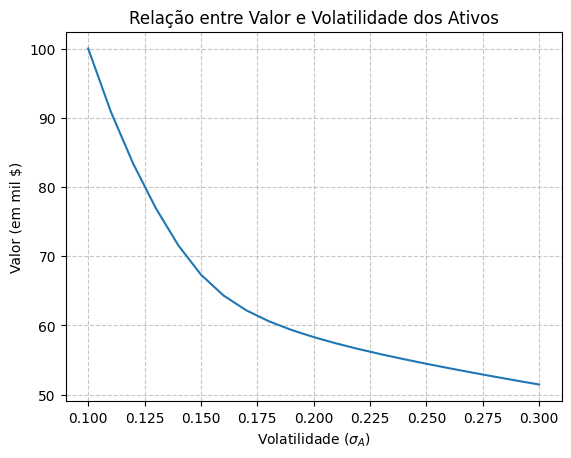

In [ ]:
# -- Gráfico 1 = ativos x sigma_a --
plt.plot(sigma_a_intervalo, at_sols/1000);                    # gera a curva de sigma_a x at
plt.title('Relação entre Valor e Volatilidade dos Ativos');   # título do gráfico
plt.xlabel('Volatilidade ($\sigma_A$)')                       # título do eixo horizontal
plt.ylabel('Valor (em mil $)')                                # título do eixo vertical
plt.grid(True, linestyle='--', alpha=0.7)                     # exibe grade no formato '---' com 70% de opacidade
plt.show()                                                    # mostra figura (padrão 6,4 x 4,8 pols)

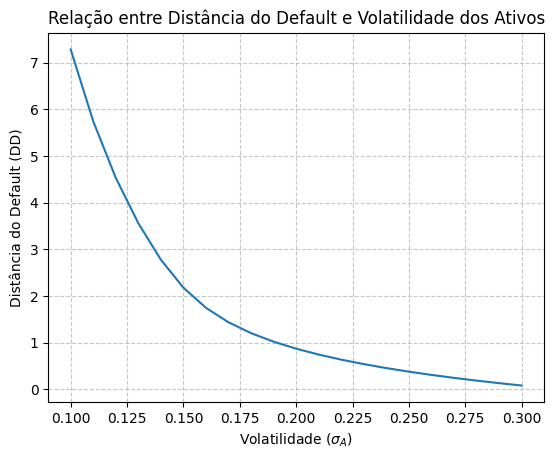

In [ ]:
# -- Gráfico 2 = DD x sigma_a --
plt.plot(sigma_a_intervalo, dd)                                               # gera a curva de sigma_a x DD
plt.title('Relação entre Distância do Default e Volatilidade dos Ativos')     # título do gráfico
plt.xlabel('Volatilidade ($\sigma_A$)');                                      # título do eixo horizontal
plt.ylabel('Distância do Default (DD)')                                       # título do eixo vertical
plt.grid(True, linestyle = '--', alpha=0.7)                                   # exibe grade no formato '---' com 70% de opacidade
plt.show()                                                                    # mostra a figura (6,4 x 4,8 pols)

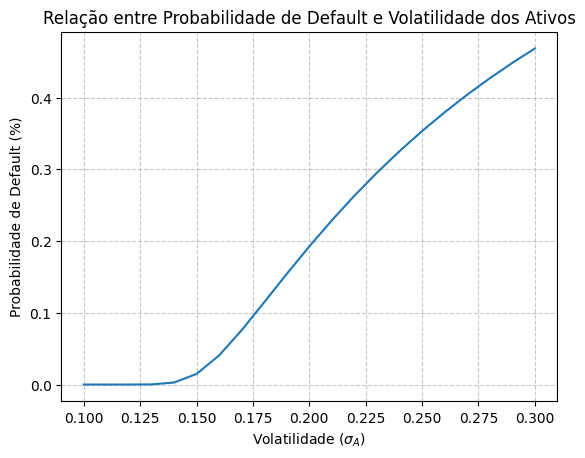

In [ ]:
# -- Gráfico 3 = PD x sigma_a --
plt.plot(sigma_a_intervalo, probd)                                            # gera a curva de sigma_a x PD
plt.title('Relação entre Probabilidade de Default e Volatilidade dos Ativos') # título do gráfico
plt.xlabel('Volatilidade ($\sigma_A$)')                                       # título do eixo horizontal
plt.ylabel('Probabilidade de Default (%)')                                    # título do eixo vertical
plt.grid(True, linestyle = '--', alpha=0.7)                                   # exibe grade no formato '---' com 70% de opacidade
plt.show()                                                                    # mostra a figura (padrão 6,4 x 4,8 pols)

### **Análise dos Resultados**

---

* <u>Estrutura de Endividamento</u>: À medida que a volatilidade dos ativos ($\sf σ_A$) aumenta, para manter uma volatilidade do equity ($\sf σ_E$
​) constante, o valor implícito dos ativos ($\sf A_t$) tende a ser menor ou a estrutura de capital torna-se mais arriscada. Isso reduz a $\sf DD$ e aumenta a $\sf PD$.
* <u>Variação de</u> $\sf σ_E$: Ao reduzir $\sf σ_E$ de $\sf 0.4$ para $\sf 0.2$ (mantendo $\sf σ_A=0.3$), a $\sf PD$ diminui significativamente. Isso ocorre porque uma menor volatilidade do <i>equity</i>, dado um mesmo risco operacional ($\sf σ_A$), implica que o valor de mercado dos ativos está muito mais acima do nível da dívida ($\sf L$), aumentando a margem de segurança e a distância ao default.

## **Referências**

---

HULL, J. **<i>Risk Management and Financial Institutions**</i>. John Wiley & Sons, 2023.

JURČA, P. **Quantitative methods in risk management**. Faculty of Mathematics, Physics and Informatics. Comenius University of Bratislava. Disponível em < http://www.iam.fmph.uniba.sk/institute/jurca/ > Acesso em: 02 maio 2026.

KHURANA, B. Credit Risk: Expected and Unexpected Losses. **finRGB**, 16 de junho de 2016. Disponível em < https://www.finrgb.com/swatches/credit-risk-expected-unexpected-losses-frm-part-1/ >. Acesso em: 03 maio 2026.

OLIVEIRA, A. **Notas de Aula - Gestão de Riscos**. MBA em Engenharia Financeira. Escola Politécnica da USP. São Paulo, 2026.

SCHROECK, G. **Risk Management and Value Creation in Financial Institutions**. John Wiley & Sons. New York, 2002.